# Week 1 — Assignment 1
## Understanding and Training a Neural Network

This notebook covers key terms, tensor operations, a simple neural network, training/validation loss, and comparison of two learning rates.

## 1. Key terms
- **Neuron:** a small calculation unit in a neural network.
- **Weight:** a value the model learns.
- **Bias:** an extra value the model learns.
- **Epoch:** one full pass through the training data.
- **Batch:** a group of examples processed together.
- **Learning rate:** controls how much the model changes its weights during training.

## 2. Import libraries

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
print('PyTorch version:', torch.__version__)

PyTorch version: 2.14.1+cpu


## 3. Tensor operations
A tensor is a container for numbers.

In [2]:
a = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
b = torch.tensor([[5, 6], [7, 8]], dtype=torch.float32)
print('Tensor a:\n', a)
print('Shape:', a.shape)
print('Reshape:', a.reshape(4))
print('Element-wise multiplication:\n', a * b)
print('Matrix multiplication:\n', torch.matmul(a, b))
print('Indexing:', a[1, 0].item())

Tensor a:
 tensor([[1., 2.],
        [3., 4.]])
Shape: torch.Size([2, 2])
Reshape: tensor([1., 2., 3., 4.])
Element-wise multiplication:
 tensor([[ 5., 12.],
        [21., 32.]])
Matrix multiplication:
 tensor([[19., 22.],
        [43., 50.]])
Indexing: 3.0


## 4. Create synthetic regression data
We create data following approximately **y = 2x + 1**.

In [3]:
x = torch.linspace(0, 10, 120).reshape(-1, 1)
y = 2 * x + 1 + 0.2 * torch.randn_like(x)
train_end = int(0.70 * len(x))
val_end = int(0.85 * len(x))
x_train, y_train = x[:train_end], y[:train_end]
x_val, y_val = x[train_end:val_end], y[train_end:val_end]
x_test, y_test = x[val_end:], y[val_end:]
print('Training:', len(x_train), 'Validation:', len(x_val), 'Testing:', len(x_test))

Training: 84 Validation: 18 Testing: 18


## 5. Build and train a neural network

In [4]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
    def forward(self, x):
        return self.layers(x)

def train_model(learning_rate, epochs=150):
    model = SimpleNet()
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        loss = loss_fn(model(x_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            train_losses.append(loss_fn(model(x_train), y_train).item())
            val_losses.append(loss_fn(model(x_val), y_val).item())
    return model, train_losses, val_losses

model1, train1, val1 = train_model(0.001)
model2, train2, val2 = train_model(0.01)
print('Final validation loss, LR 0.001:', round(val1[-1], 4))
print('Final validation loss, LR 0.01:', round(val2[-1], 4))

Final validation loss, LR 0.001: 0.3053
Final validation loss, LR 0.01: 0.0444


## 6. Plot training and validation loss

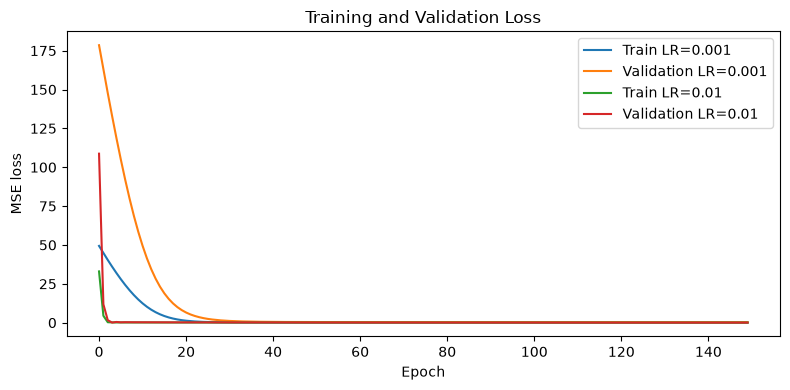

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(train1, label='Train LR=0.001')
plt.plot(val1, label='Validation LR=0.001')
plt.plot(train2, label='Train LR=0.01')
plt.plot(val2, label='Validation LR=0.01')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Assignment summary
We created numerical data, trained a neural network, plotted training and validation loss, and compared two learning rates. The lower validation loss indicates the better result for this run.